In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from dotenv import load_dotenv, find_dotenv
from IPython.display import display

_env_file = find_dotenv()
REPO_DIR = Path(_env_file).parent.resolve()
load_dotenv(_env_file)

True

In [2]:
# ── Selecciona l'experiment a analitzar ─────────────────────────────────────
# "" = últim experiment creat
# "20260414_153000" = experiment concret
experiment = ""

In [3]:
# ── Carrega config i resultats ───────────────────────────────────────────────
RESULTS_BASE = REPO_DIR / "results" / "sweep_bias_accuracy"

if experiment == "":
    candidates = sorted([d for d in RESULTS_BASE.iterdir() if d.is_dir()])
    if not candidates:
        raise FileNotFoundError(f"No hi ha experiments a {RESULTS_BASE}")
    EXP_DIR = candidates[-1]
    print(f"Carregant últim experiment: {EXP_DIR.name}")
else:
    EXP_DIR = RESULTS_BASE / experiment
    if not EXP_DIR.exists():
        available = [d.name for d in RESULTS_BASE.iterdir() if d.is_dir()]
        raise FileNotFoundError(f"Experiment '{experiment}' no trobat.\nDisponibles: {available}")

with open(EXP_DIR / "config.json") as f:
    config = json.load(f)

RESULTS_FILE = EXP_DIR / "sweep_results_v2.json"
N_RUNS = config["N_RUNS"]

if not RESULTS_FILE.exists():
    raise FileNotFoundError(f"Encara no hi ha resultats a {RESULTS_FILE}")

with open(RESULTS_FILE) as f:
    all_results = json.load(f)

total_configs = len(config['ALPHAS']) * len(config['LAYER_SIZES']) * N_RUNS
print(f"Experiment : {EXP_DIR.name}")
print(f"Config     : {config}")
print(f"Runs completats: {len(all_results)} / {total_configs}")

Carregant últim experiment: 20260426_025714
Experiment : 20260426_025714
Config     : {'N_RUNS': 5, 'BASE_SEED': 42, 'ALPHAS': [0.2, 0.4, 0.6, 0.8, 1.0, 1.2], 'LAYER_SIZES': [4, 8, 12, 16, 20, 24, 28, 32, 48], 'MAX_EPOCHS': 100, 'PATIENCE': 10, 'BATCH_SIZE': 32, 'FAIRNESS_LOSS': 'tpr_parity'}
Runs completats: 270 / 270


In [4]:
# ── Taula: mitjana ± std per configuració ───────────────────────────────────
df_runs = pd.DataFrame(all_results)

METRICS = ['accuracy', 'auc_all', 'tpr_male', 'tpr_female', 'tpr_gap', 'gender_auc_last_layer']

agg = df_runs.groupby(['alpha', 'ls'])[METRICS].agg(['mean', 'std']).reset_index()
agg.columns = ['alpha', 'ls'] + [f'{m}_{s}' for m, s in agg.columns[2:]]
agg['n_runs'] = df_runs.groupby(['alpha', 'ls']).size().values
agg = agg.sort_values(['alpha', 'ls']).reset_index(drop=True)

display_df = agg[['alpha', 'ls', 'n_runs']].copy()
for m in METRICS:
    display_df[m] = agg[f'{m}_mean'].map('{:.3f}'.format) + ' ± ' + agg[f'{m}_std'].map('{:.3f}'.format)

display(display_df.style
        .set_caption(f'Resultats sweep (mitjana ± std, N={N_RUNS} runs per config)'))

,alpha,ls,n_runs,accuracy,auc_all,tpr_male,tpr_female,tpr_gap,gender_auc_last_layer
0,0.200000,4,5,0.794 ± 0.020,0.871 ± 0.017,0.700 ± 0.025,0.723 ± 0.046,0.045 ± 0.022,0.611 ± 0.021
1,0.200000,8,5,0.794 ± 0.023,0.868 ± 0.018,0.692 ± 0.035,0.721 ± 0.052,0.055 ± 0.030,0.667 ± 0.029
2,0.200000,12,5,0.795 ± 0.024,0.869 ± 0.017,0.727 ± 0.040,0.735 ± 0.046,0.031 ± 0.007,0.694 ± 0.040
3,0.200000,16,5,0.797 ± 0.021,0.871 ± 0.016,0.739 ± 0.051,0.741 ± 0.051,0.057 ± 0.031,0.721 ± 0.039
4,0.200000,20,5,0.797 ± 0.014,0.871 ± 0.015,0.730 ± 0.056,0.723 ± 0.044,0.075 ± 0.029,0.753 ± 0.020
5,0.200000,24,5,0.799 ± 0.016,0.871 ± 0.015,0.730 ± 0.039,0.723 ± 0.033,0.036 ± 0.021,0.771 ± 0.030
6,0.200000,28,5,0.790 ± 0.016,0.872 ± 0.015,0.702 ± 0.042,0.744 ± 0.040,0.059 ± 0.041,0.794 ± 0.030
7,0.200000,32,5,0.798 ± 0.017,0.871 ± 0.016,0.736 ± 0.039,0.728 ± 0.045,0.042 ± 0.026,0.812 ± 0.048
8,0.200000,48,5,0.796 ± 0.022,0.870 ± 0.017,0.712 ± 0.034,0.732 ± 0.042,0.044 ± 0.017,0.847 ± 0.027
9,0.400000,4,5,0.792 ± 0.019,0.871 ± 0.017,0.700 ± 0.032,0.723 ± 0.050,0.048 ± 0.025,0.609 ± 0.020


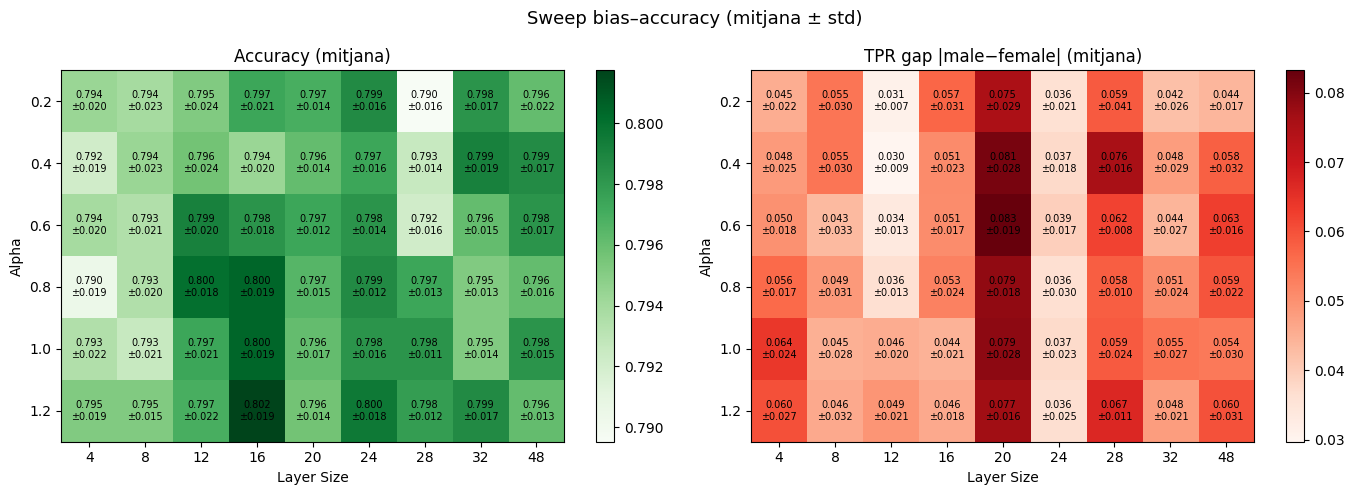

In [5]:
# ── Heatmaps: accuracy i tpr_gap ────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric, cmap, title in [
    (axes[0], 'accuracy', 'Greens', 'Accuracy (mitjana)'),
    (axes[1], 'tpr_gap',  'Reds',   'TPR gap |male−female| (mitjana)'),
]:
    pivot_mean = agg.pivot(index='alpha', columns='ls', values=f'{metric}_mean')
    pivot_std  = agg.pivot(index='alpha', columns='ls', values=f'{metric}_std')

    im = ax.imshow(pivot_mean.values, cmap=cmap, aspect='auto')
    ax.set_xticks(range(len(pivot_mean.columns)))
    ax.set_xticklabels(pivot_mean.columns)
    ax.set_yticks(range(len(pivot_mean.index)))
    ax.set_yticklabels(pivot_mean.index)
    ax.set_xlabel('Layer Size')
    ax.set_ylabel('Alpha')
    ax.set_title(title)
    for i in range(len(pivot_mean.index)):
        for j in range(len(pivot_mean.columns)):
            m_val = pivot_mean.values[i, j]
            s_val = pivot_std.values[i, j]
            if not np.isnan(m_val):
                ax.text(j, i, f'{m_val:.3f}\n±{s_val:.3f}',
                        ha='center', va='center', fontsize=7)
    plt.colorbar(im, ax=ax)

plt.suptitle('Sweep bias–accuracy (mitjana ± std)', fontsize=13)
plt.tight_layout()
plt.savefig(EXP_DIR / 'sweep_heatmaps_v2.png', dpi=150, bbox_inches='tight')
plt.show()

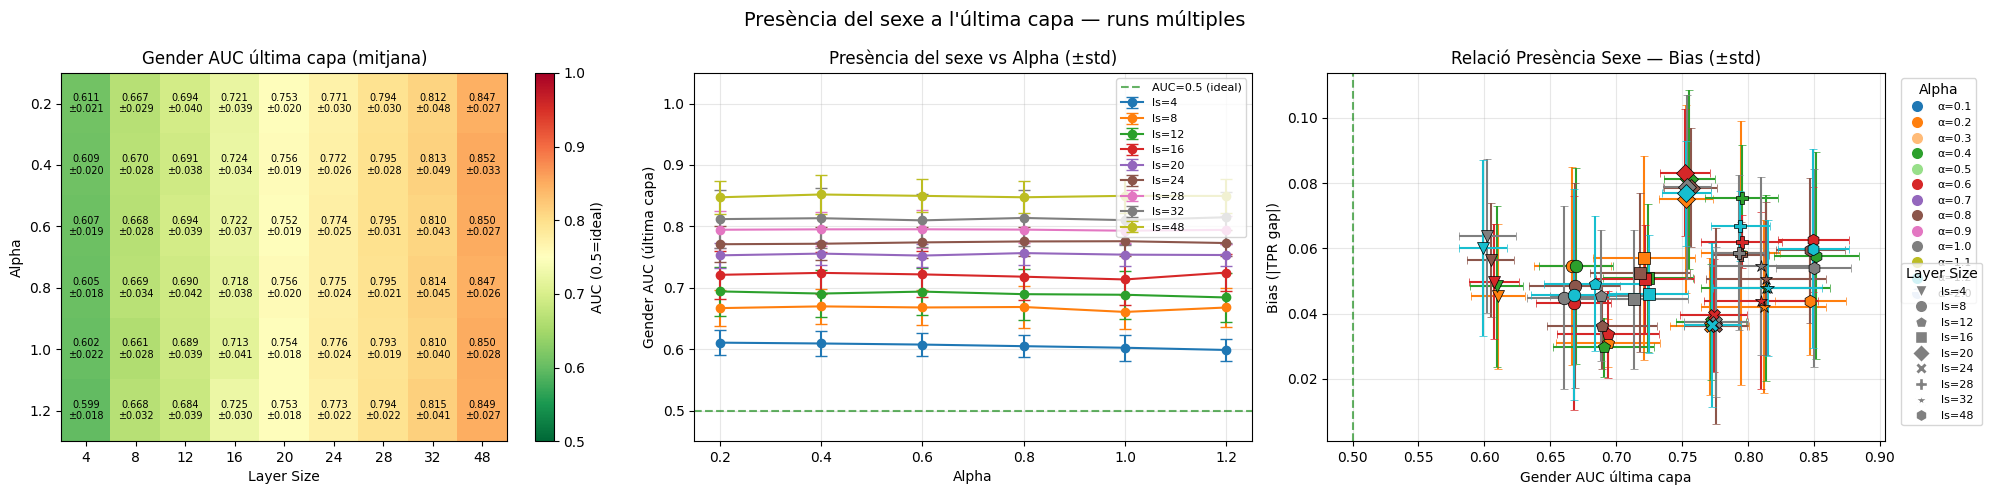

In [6]:
# ── Gender AUC: heatmap + corbes + scatter ───────────────────────────────────
df_gender = agg.dropna(subset=['gender_auc_last_layer_mean']).copy()

if df_gender.empty:
    print("No hi ha dades de 'gender_auc_last_layer' als resultats.")
else:
    fig, axes = plt.subplots(1, 3, figsize=(20, 5))

    # 1. Heatmap
    pivot_gauc_m = df_gender.pivot(index='alpha', columns='ls', values='gender_auc_last_layer_mean')
    pivot_gauc_s = df_gender.pivot(index='alpha', columns='ls', values='gender_auc_last_layer_std')
    im = axes[0].imshow(pivot_gauc_m.values, cmap='RdYlGn_r', aspect='auto', vmin=0.5, vmax=1.0)
    axes[0].set_xticks(range(len(pivot_gauc_m.columns)))
    axes[0].set_xticklabels(pivot_gauc_m.columns)
    axes[0].set_yticks(range(len(pivot_gauc_m.index)))
    axes[0].set_yticklabels(pivot_gauc_m.index)
    axes[0].set_xlabel('Layer Size')
    axes[0].set_ylabel('Alpha')
    axes[0].set_title('Gender AUC última capa (mitjana)')
    for i in range(len(pivot_gauc_m.index)):
        for j in range(len(pivot_gauc_m.columns)):
            v, s = pivot_gauc_m.values[i, j], pivot_gauc_s.values[i, j]
            if not np.isnan(v):
                axes[0].text(j, i, f'{v:.3f}\n±{s:.3f}', ha='center', va='center', fontsize=7)
    plt.colorbar(im, ax=axes[0], label='AUC (0.5=ideal)')

    # 2. Corbes
    for ls in sorted(df_gender['ls'].unique()):
        sub = df_gender[df_gender['ls'] == ls].sort_values('alpha')
        axes[1].errorbar(
            sub['alpha'], sub['gender_auc_last_layer_mean'],
            yerr=sub['gender_auc_last_layer_std'],
            marker='o', capsize=4, label=f'ls={ls}'
        )
    axes[1].axhline(0.5, color='green', linestyle='--', alpha=0.6, label='AUC=0.5 (ideal)')
    axes[1].set_xlabel('Alpha')
    axes[1].set_ylabel('Gender AUC (última capa)')
    axes[1].set_title('Presència del sexe vs Alpha (±std)')
    axes[1].set_ylim(0.45, 1.05)
    axes[1].legend(fontsize=8)
    axes[1].grid(True, alpha=0.3)

    # 3. Scatter
    alpha_colors = {0.1: '#1f77b4', 0.2: '#ff7f0e', 0.3: '#ffbb78', 0.4: '#2ca02c',
                    0.5: '#98df8a', 0.6: '#d62728', 0.7: '#9467bd', 0.8: '#8c564b',
                    0.9: '#e377c2', 1.0: '#7f7f7f', 1.1: '#bcbd22', 1.2: '#17becf',
                    2.0: '#aec7e8'}
    ls_markers   = {4: 'v', 8: 'o', 12: 'p', 16: 's', 20: 'D', 24: 'X', 28: 'P', 32: '*', 48: 'h'}
    for _, row in df_gender.iterrows():
        a, l = row['alpha'], row['ls']
        axes[2].errorbar(
            row['gender_auc_last_layer_mean'], row['tpr_gap_mean'],
            xerr=row['gender_auc_last_layer_std'], yerr=row['tpr_gap_std'],
            fmt=ls_markers.get(l, 'x'), color=alpha_colors.get(a, 'gray'),
            markersize=9, capsize=3, markeredgecolor='black', markeredgewidth=0.5
        )
    axes[2].axvline(0.5, color='green', linestyle='--', alpha=0.6, label='Gender AUC=0.5 (ideal)')
    axes[2].set_xlabel('Gender AUC última capa')
    axes[2].set_ylabel('Bias (|TPR gap|)')
    axes[2].set_title('Relació Presència Sexe — Bias (±std)')
    axes[2].grid(True, alpha=0.3)

    from matplotlib.lines import Line2D
    legend_alpha = [Line2D([0],[0], marker='o', color='w', markerfacecolor=c,
                           markersize=9, label=f'α={a}') for a, c in alpha_colors.items()]
    legend_ls    = [Line2D([0],[0], marker=m, color='w', markerfacecolor='gray',
                           markersize=9, label=f'ls={l}') for l, m in ls_markers.items()]
    leg1 = axes[2].legend(handles=legend_alpha, title='Alpha', loc='upper left',
                          bbox_to_anchor=(1.02, 1), fontsize=8)
    axes[2].add_artist(leg1)
    axes[2].legend(handles=legend_ls, title='Layer Size', loc='upper left',
                   bbox_to_anchor=(1.02, 0.5), fontsize=8)

    plt.suptitle("Presència del sexe a l'última capa — runs múltiples", fontsize=14)
    plt.tight_layout()
    plt.savefig(EXP_DIR / 'gender_presence_last_layer_v2.png', dpi=150, bbox_inches='tight')
    plt.show()

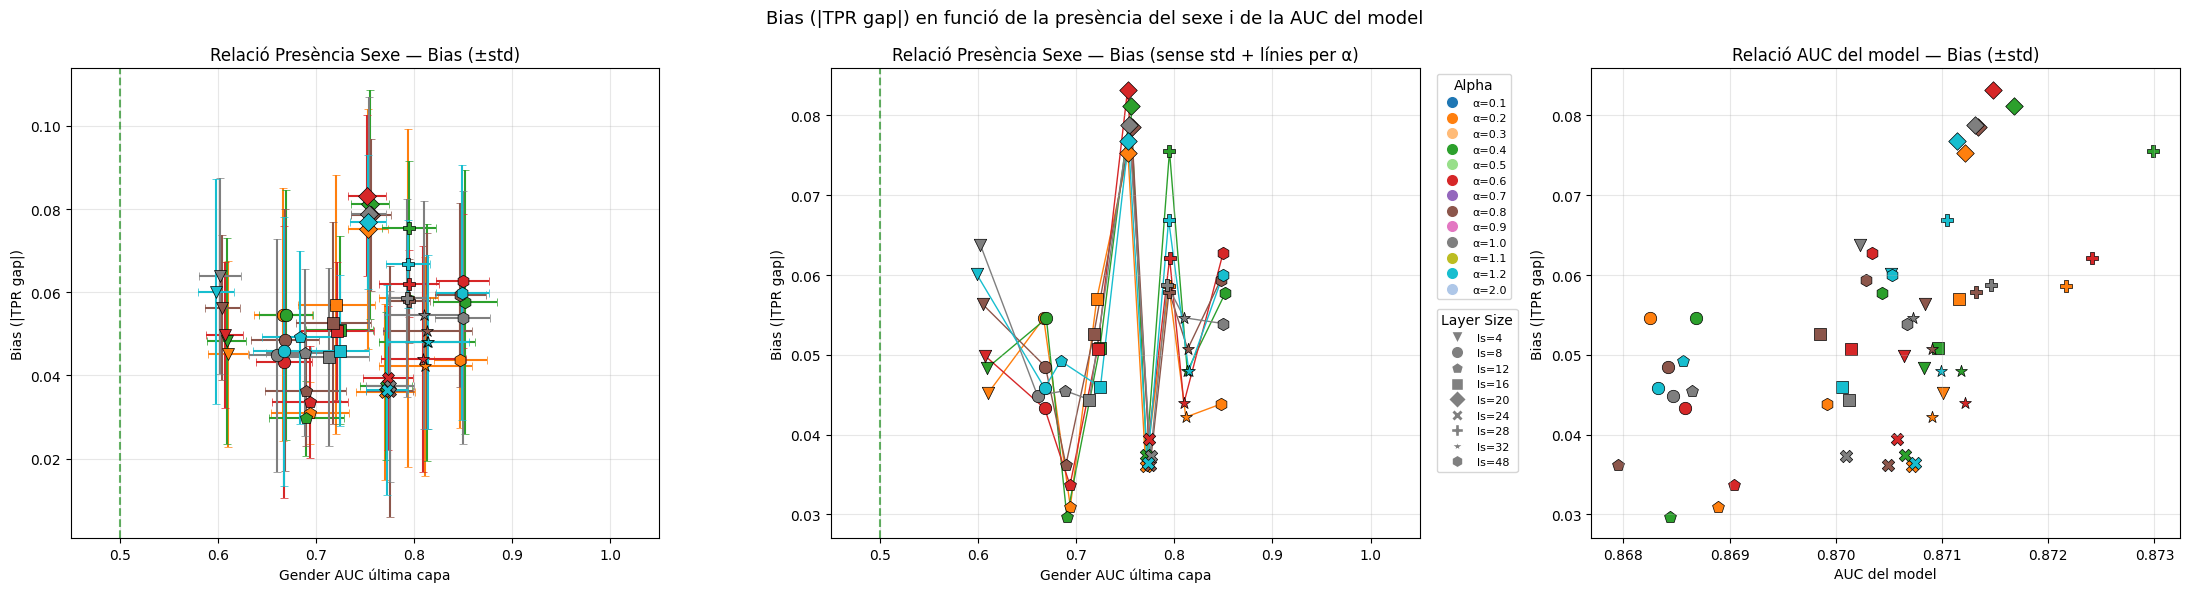

In [7]:
# ── Scatter: Gender AUC vs Bias  |  Model AUC vs Bias ───────────────────────
# None = mostra tots els alpha; llista = filtra, ex: [0.1, 0.5, 1.0]
SHOW_ALPHAS = None # [0.2, 0.3, 0.4, 0.5]

alpha_colors = {0.1: '#1f77b4', 0.2: '#ff7f0e', 0.3: '#ffbb78', 0.4: '#2ca02c',
                0.5: '#98df8a', 0.6: '#d62728', 0.7: '#9467bd', 0.8: '#8c564b',
                0.9: '#e377c2', 1.0: '#7f7f7f', 1.1: '#bcbd22', 1.2: '#17becf',
                2.0: '#aec7e8'}
ls_markers   = {4: 'v', 8: 'o', 12: 'p', 16: 's', 20: 'D', 24: 'X', 28: 'P', 32: '*', 48: 'h'}

fig, axes = plt.subplots(1, 3, figsize=(22, 6))

scatter_configs = [
    (axes[0], 'gender_auc_last_layer', 'Gender AUC última capa',
     'Relació Presència Sexe — Bias (±std)',
     0.5, 'Gender AUC=0.5 (ideal)', (0.45, 1.05)),

    (axes[1], 'gender_auc_last_layer', 'Gender AUC última capa',
     'Relació Presència Sexe — Bias (sense std + línies per α)',
     0.5, 'Gender AUC=0.5 (ideal)', (0.45, 1.05)),

    (axes[2], 'auc_all', 'AUC del model',
     'Relació AUC del model — Bias (±std)',
     None, None, None),
]

for ax, x_metric, x_label, title, vline, vline_label, xlim in scatter_configs:
    sub = agg.dropna(subset=[f'{x_metric}_mean']).copy()
    if SHOW_ALPHAS is not None:
        sub = sub[sub['alpha'].isin(SHOW_ALPHAS)]

    if ax == axes[1]:
        # gràfica del mig: línies per alpha + marcadors per ls
        for a, df_a in sub.groupby('alpha'):
            df_a = df_a.sort_values(f'{x_metric}_mean')
            color = alpha_colors.get(a, 'gray')
            # línia connectora sense marcadors
            ax.plot(
                df_a[f'{x_metric}_mean'],
                df_a['tpr_gap_mean'],
                color=color,
                linewidth=1,
                zorder=1
            )
            # marcador per ls sobre cada punt
            for _, row in df_a.iterrows():
                ax.scatter(
                    row[f'{x_metric}_mean'], row['tpr_gap_mean'],
                    marker=ls_markers.get(row['ls'], 'x'),
                    color=color,
                    s=80,
                    edgecolor='black',
                    linewidth=0.5,
                    zorder=2
                )
    else:
        # gràfiques normal + dreta
        for _, row in sub.iterrows():
            a, l = row['alpha'], row['ls']

            if ax == axes[2]:  # dreta sense std
                ax.scatter(
                    row[f'{x_metric}_mean'], row['tpr_gap_mean'],
                    marker=ls_markers.get(l, 'x'),
                    color=alpha_colors.get(a, 'gray'),
                    s=80,
                    edgecolor='black',
                    linewidth=0.5
                )
            else:  # esquerra amb std
                ax.errorbar(
                    row[f'{x_metric}_mean'], row['tpr_gap_mean'],
                    xerr=row[f'{x_metric}_std'],
                    yerr=row['tpr_gap_std'],
                    fmt=ls_markers.get(l, 'x'),
                    color=alpha_colors.get(a, 'gray'),
                    markersize=9,
                    capsize=3,
                    markeredgecolor='black',
                    markeredgewidth=0.5
                )
    if vline is not None:
        ax.axvline(vline, color='green', linestyle='--', alpha=0.6, label=vline_label)
    if xlim is not None:
        ax.set_xlim(xlim)
    ax.set_xlabel(x_label)
    ax.set_ylabel('Bias (|TPR gap|)')
    ax.set_title(title)
    ax.grid(True, alpha=0.3)

active_alphas = SHOW_ALPHAS if SHOW_ALPHAS is not None else sorted(alpha_colors.keys())
from matplotlib.lines import Line2D
legend_alpha = [Line2D([0],[0], marker='o', color='w', markerfacecolor=alpha_colors[a],
                       markersize=9, label=f'α={a}') for a in active_alphas if a in alpha_colors]
legend_ls    = [Line2D([0],[0], marker=m, color='w', markerfacecolor='gray',
                       markersize=9, label=f'ls={l}') for l, m in ls_markers.items()]
leg1 = axes[1].legend(handles=legend_alpha, title='Alpha', loc='upper left',
                      bbox_to_anchor=(1.02, 1), fontsize=8)
axes[1].add_artist(leg1)
axes[1].legend(handles=legend_ls, title='Layer Size', loc='upper left',
               bbox_to_anchor=(1.02, 0.5), fontsize=8)

plt.suptitle('Bias (|TPR gap|) en funció de la presència del sexe i de la AUC del model', fontsize=13)
plt.tight_layout()
plt.savefig(EXP_DIR / 'scatter_gender_auc_vs_model_auc_v2.png', dpi=150, bbox_inches='tight')
plt.show()

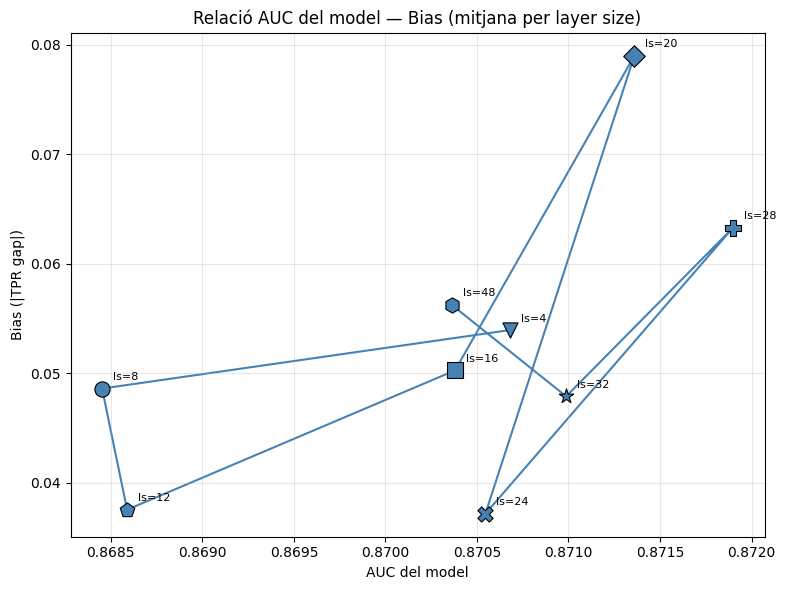

In [13]:
# ── Scatter: AUC del model vs Bias – mitjana per ls ─────────────────────────
fig, ax = plt.subplots(figsize=(8, 6))

x_metric = 'auc_all'

sub = agg.dropna(subset=[f'{x_metric}_mean']).copy()
if SHOW_ALPHAS is not None:
    sub = sub[sub['alpha'].isin(SHOW_ALPHAS)]

# Mitjana per ls (agrupant tots els alphas)
grouped = sub.groupby('ls').agg(
    x_mean=(f'{x_metric}_mean', 'mean'),
    y_mean=('tpr_gap_mean', 'mean'),
).reset_index().sort_values('ls')

# Línia connectora
ax.plot(grouped['x_mean'], grouped['y_mean'],
        color='steelblue', linewidth=1.5, zorder=1)

# Marcadors per ls
for _, row in grouped.iterrows():
    ax.scatter(row['x_mean'], row['y_mean'],
               marker=ls_markers.get(int(row['ls']), 'x'),
               color='steelblue', s=120,
               edgecolor='black', linewidth=0.8, zorder=2)
    ax.annotate(f"ls={int(row['ls'])}", (row['x_mean'], row['y_mean']),
                textcoords='offset points', xytext=(8, 6), fontsize=8)

ax.set_xlabel('AUC del model')
ax.set_ylabel('Bias (|TPR gap|)')
ax.set_title('Relació AUC del model — Bias (mitjana per layer size)')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(EXP_DIR / 'scatter_model_auc_vs_bias_mean_per_ls.png', dpi=150, bbox_inches='tight')
plt.show()

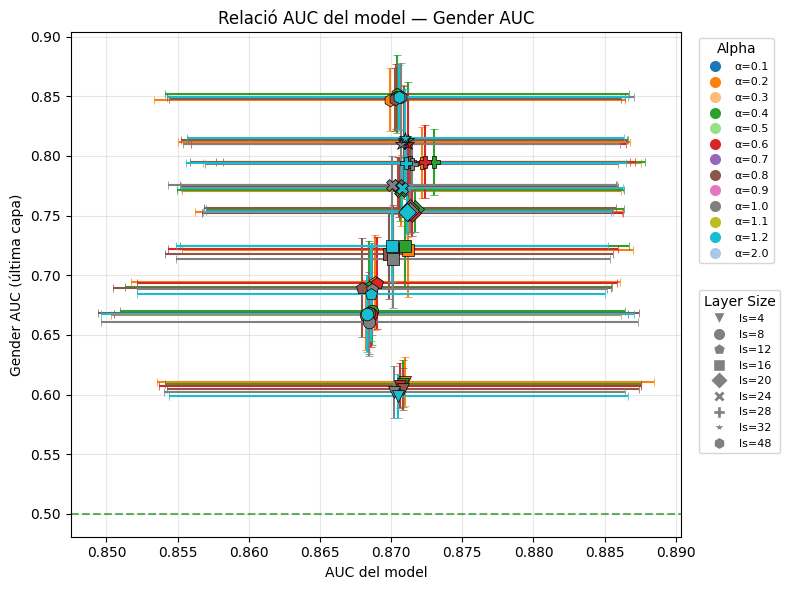

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))

sub = agg.dropna(subset=['auc_all_mean', 'gender_auc_last_layer_mean']).copy()

for _, row in sub.iterrows():
    a, l = row['alpha'], row['ls']
    ax.errorbar(
        row['auc_all_mean'], row['gender_auc_last_layer_mean'],
        xerr=row['auc_all_std'], yerr=row['gender_auc_last_layer_std'],
        fmt=ls_markers.get(l, 'x'),
        color=alpha_colors.get(a, 'gray'),
        markersize=9,
        capsize=3,
        markeredgecolor='black',
        markeredgewidth=0.5
    )

# Línia ideal de no-informació en gènere
ax.axhline(0.5, color='green', linestyle='--', alpha=0.6,
           label='Gender AUC = 0.5 (ideal)')

ax.set_xlabel('AUC del model')
ax.set_ylabel('Gender AUC (última capa)')
ax.set_title('Relació AUC del model — Gender AUC')
ax.grid(True, alpha=0.3)

# Llegendes (mateix estil que abans)
from matplotlib.lines import Line2D

legend_alpha = [
    Line2D([0],[0], marker='o', color='w', markerfacecolor=c,
           markersize=9, label=f'α={a}')
    for a, c in alpha_colors.items()
]

legend_ls = [
    Line2D([0],[0], marker=m, color='w', markerfacecolor='gray',
           markersize=9, label=f'ls={l}')
    for l, m in ls_markers.items()
]

leg1 = ax.legend(handles=legend_alpha, title='Alpha',
                 loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=8)
ax.add_artist(leg1)

ax.legend(handles=legend_ls, title='Layer Size',
          loc='upper left', bbox_to_anchor=(1.02, 0.5), fontsize=8)

plt.tight_layout()
plt.savefig(EXP_DIR / 'scatter_auc_vs_gender_auc.png',
            dpi=150, bbox_inches='tight')
plt.show()

/tmp/ipykernel_2208456/3794530153.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data_per_config, labels=configs, patch_artist=True)
/tmp/ipykernel_2208456/3794530153.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data_per_config, labels=configs, patch_artist=True)


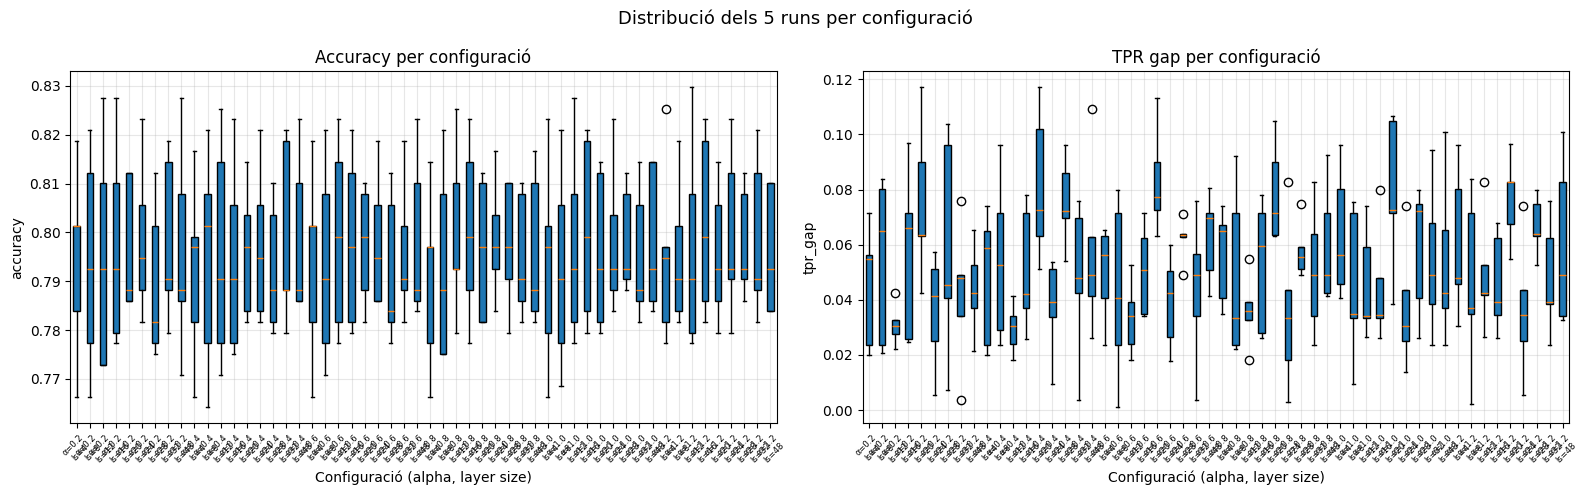

In [9]:
# ── Boxplots: distribució individual dels runs ───────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

df_runs['config'] = df_runs.apply(lambda r: f"α={r['alpha']}\nls={r['ls']}", axis=1)
configs = (df_runs.sort_values(['alpha', 'ls'])
                  .drop_duplicates('config')['config'].tolist())

for ax, metric, title in [
    (axes[0], 'accuracy', 'Accuracy per configuració'),
    (axes[1], 'tpr_gap',  'TPR gap per configuració'),
]:
    data_per_config = [
        df_runs[df_runs['config'] == c][metric].dropna().tolist()
        for c in configs
    ]
    ax.boxplot(data_per_config, labels=configs, patch_artist=True)
    ax.set_xlabel('Configuració (alpha, layer size)')
    ax.set_ylabel(metric)
    ax.set_title(title)
    ax.tick_params(axis='x', labelsize=6, rotation=45)
    ax.grid(True, alpha=0.3)

plt.suptitle(f'Distribució dels {N_RUNS} runs per configuració', fontsize=13)
plt.tight_layout()
plt.savefig(EXP_DIR / 'sweep_boxplots_v2.png', dpi=150, bbox_inches='tight')
plt.show()